# Parking Space Detection with YOLOv8

**Goal:** Detect each parking space in a camera image or video and classify it as **empty** or **occupied**.

**Pipeline:** PKLot dataset → train YOLOv8n → evaluate → test on images → measure speed → video demo → simulated IoT message

**Before you start (Google Colab):** go to *Runtime → Change runtime type → T4 GPU*, then run the cells from top to bottom.

## Step 1: Install the libraries

In [ ]:
!pip install -q ultralytics roboflow opencv-python-headless

import ultralytics
ultralytics.checks()   # shows the Python, torch and GPU versions

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## Step 2: Download the PKLot dataset (YOLO format)

1. Create a free account at [roboflow.com](https://roboflow.com).
2. Open the PKLot page: https://public.roboflow.com/object-detection/pklot
3. Choose a version, click **Download → YOLOv8 → Show download code**.
4. Copy your **API key**, **workspace**, **project** and **version** into the cell below.

*Tip:* the full dataset is about 12,000 images. If training is too slow, pick a smaller version (for example the 640 resized one).

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="PASTE_YOUR_API_KEY_HERE")
project = rf.workspace("sagitova-aliya").project("pklot-qesrf")
version = project.version(2)
dataset = version.download("yolov8")
DATA_DIR  = dataset.location
DATA_YAML = f"{DATA_DIR}/data.yaml"
print("Dataset saved in:", DATA_DIR)

## Step 3: Explore the dataset

Check the class names (labels), count the images, and draw the labels on one image.

In [ ]:
import yaml, glob, os

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
print("Classes:", cfg["names"])

for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{DATA_DIR}/{split}/images/*"))
    print(f"{split:5s}: {n} images")

Classes: ['space-empty', 'space-occupied']
train: 6834 images
valid: 1956 images
test : 988 images


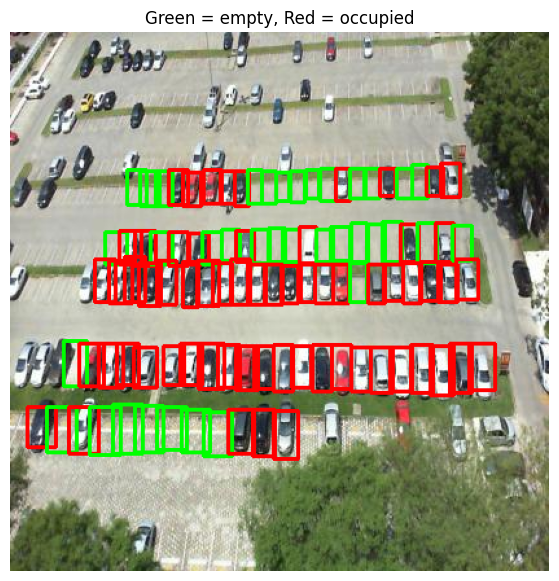

In [54]:
import cv2, random
import matplotlib.pyplot as plt

img_path = random.choice(glob.glob(f"{DATA_DIR}/train/images/*"))
lbl_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

img = cv2.imread(img_path)
h, w = img.shape[:2]
names = cfg["names"]

# YOLO label line = class x_center y_center width height (all 0-1)
with open(lbl_path) as f:
    for line in f:
        c, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        name = names[int(c)]
        color = (0, 255, 0) if "empty" in name else (0, 0, 255)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Green = empty, Red = occupied")
plt.axis("off"); plt.show()

## Step 4: Train YOLOv8n

- **yolov8n** = the *nano* model: small and fast, good for IoT devices.
- **Transfer learning:** we start from weights already trained on the COCO dataset.
- **epochs** = how many times the model sees all the training data.
- YOLO uses **gradient descent** (SGD/AdamW) and **backpropagation** to update its weights, as studied in class.
- The `hsv_v` (brightness) and `degrees` settings add **data augmentation**, which helps with shadows, rain and lighting changes.

In [55]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # small, fast model (good for IoT)

results = model.train(
    data=DATA_YAML,
    epochs=5,           # quick first test (later try 20)
    imgsz=416,          # same size as the dataset images = faster
    batch=16,
    hsv_v=0.5,          # brightness changes (lighting / shadows)
    degrees=5,          # small rotations (camera angle)
    patience=5,         # stop early if no improvement
    project="runs",
    name="pklot_yolov8n",
    exist_ok=True,      # reuse the same folder if you train again
)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PKLot-2/data.yaml, degrees=5, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pklot_yolov8n, nbs=64, nms=None, opset=None, optimize=False, optim

In [56]:
RUN_DIR = "/content/runs/detect/runs/pklot_yolov8n"
BEST    = f"{RUN_DIR}/weights/best.pt"
print(BEST)

/content/runs/detect/runs/pklot_yolov8n/weights/best.pt


## Step 5: Evaluate the model

- **Precision:** of the spaces the model called occupied, how many really were.
- **Recall:** of the spaces that really were occupied, how many the model found.
- **mAP50:** the main object-detection score (0 to 1, higher is better).
- The **confusion matrix** shows where the model mixes up empty and occupied.

In [57]:
best = YOLO(BEST)
metrics = best.val(data=DATA_YAML, split="test")

print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 976.3±363.4 MB/s, size: 35.2 KB)
val: Scanning /content/PKLot-2/test/labels... 988 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 988/988 1.1Kit/s 0.9s
val: New cache created: /content/PKLot-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 6.2it/s 9.9s
                   all        988      57436      0.979      0.976      0.992      0.818
           space-empty        853      29733       0.99      0.962      0.992      0.828
        space-occupied        808      27703      0.969       0.99      0.993      0.809
Speed: 0.5ms preprocess, 2.2ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val
Precision: 0.979
Recall:    0.976
mAP50:     0.992
m

results.png


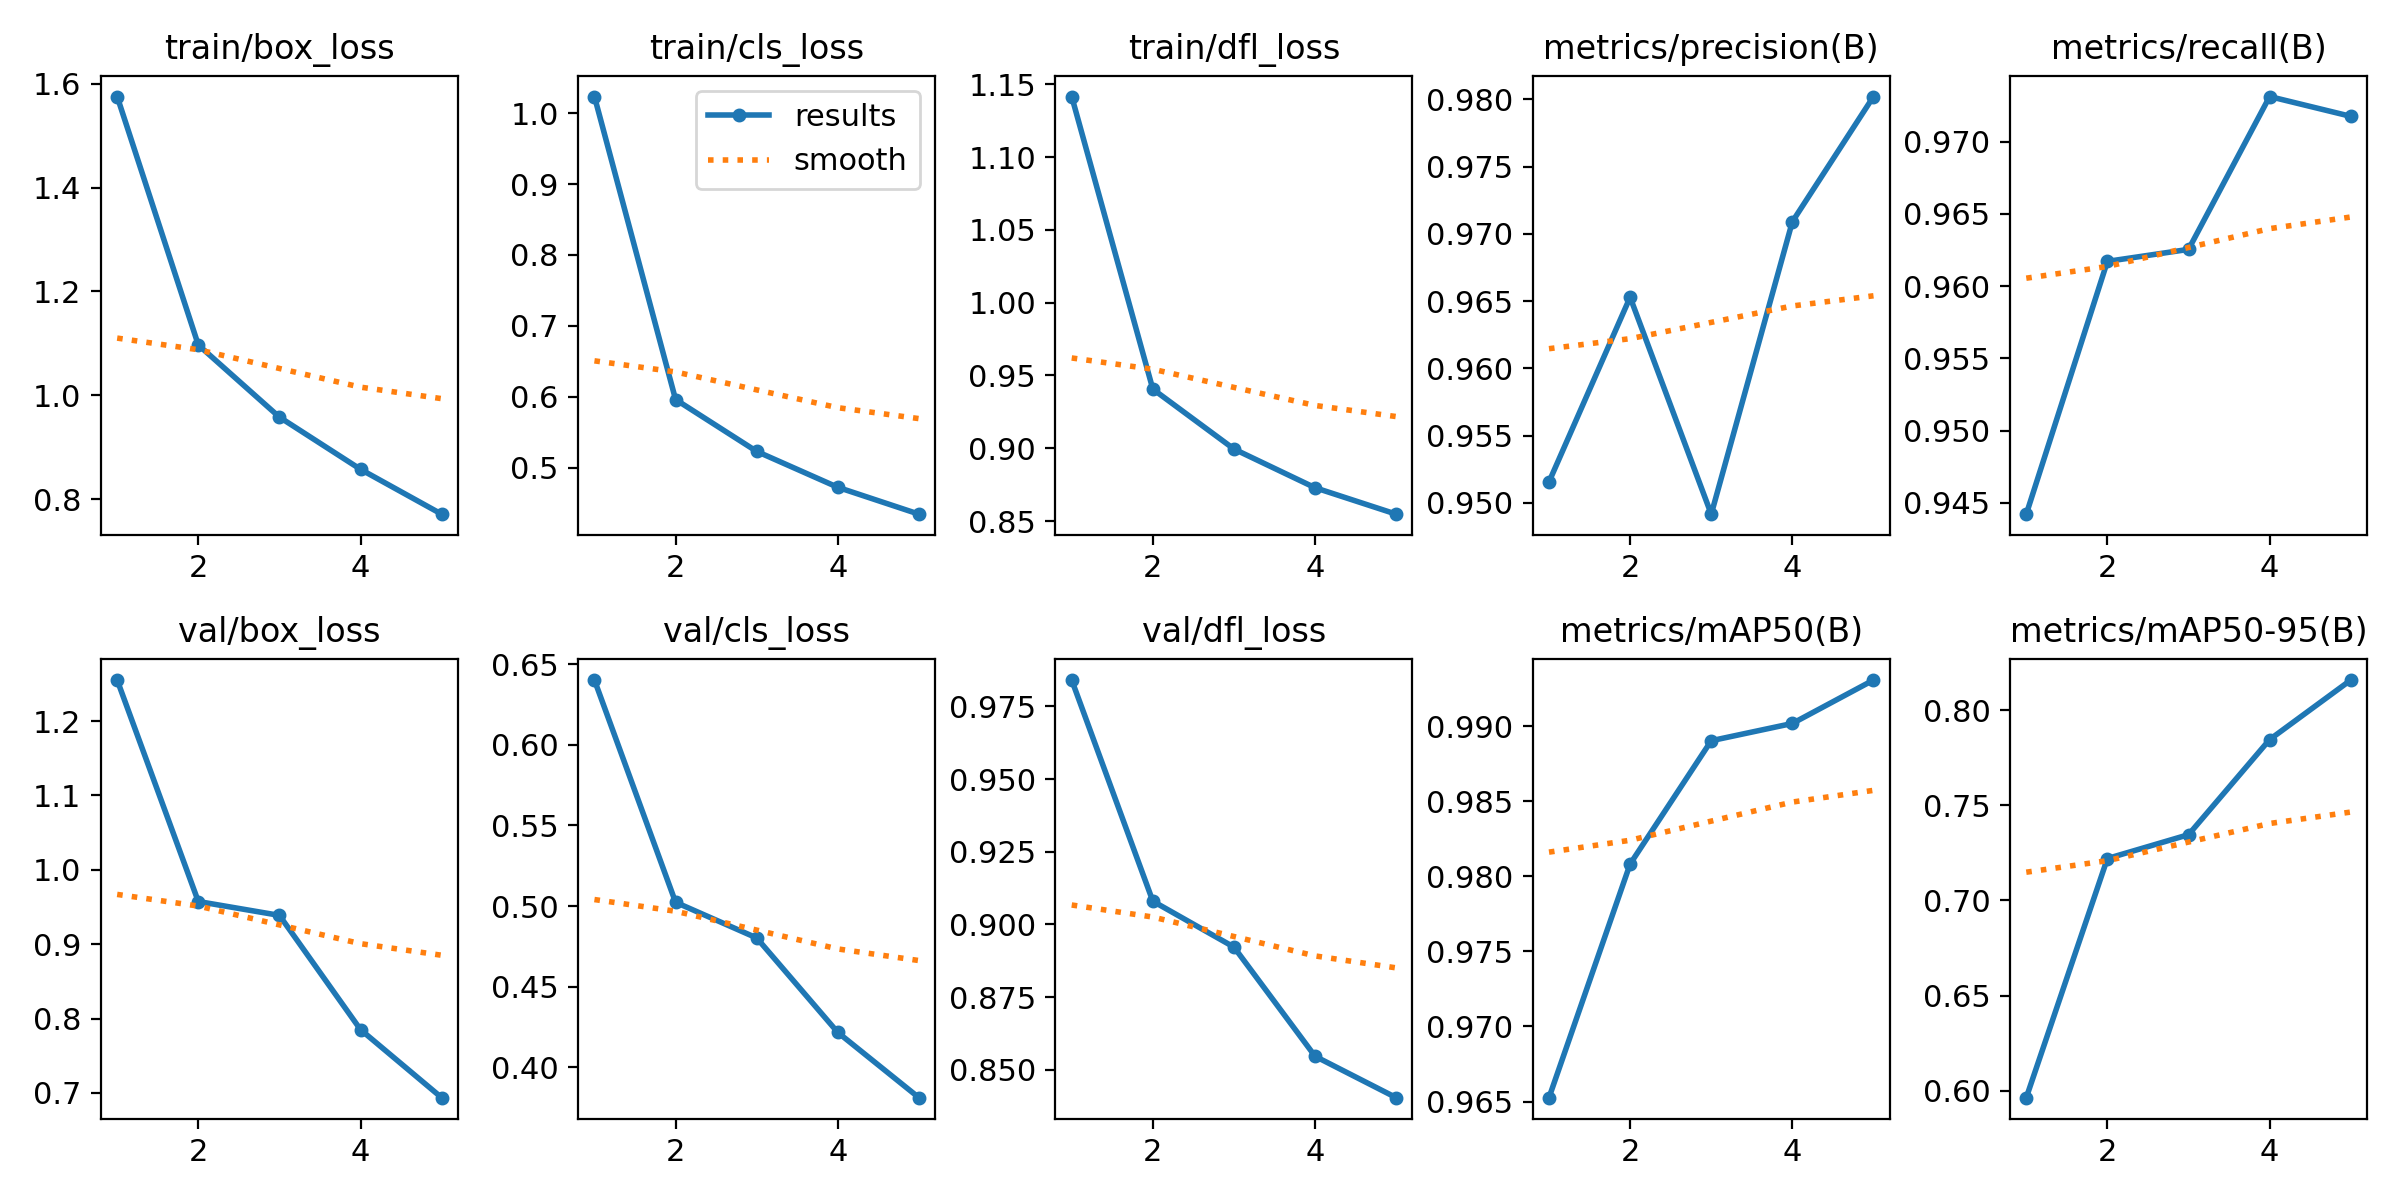

confusion_matrix.png


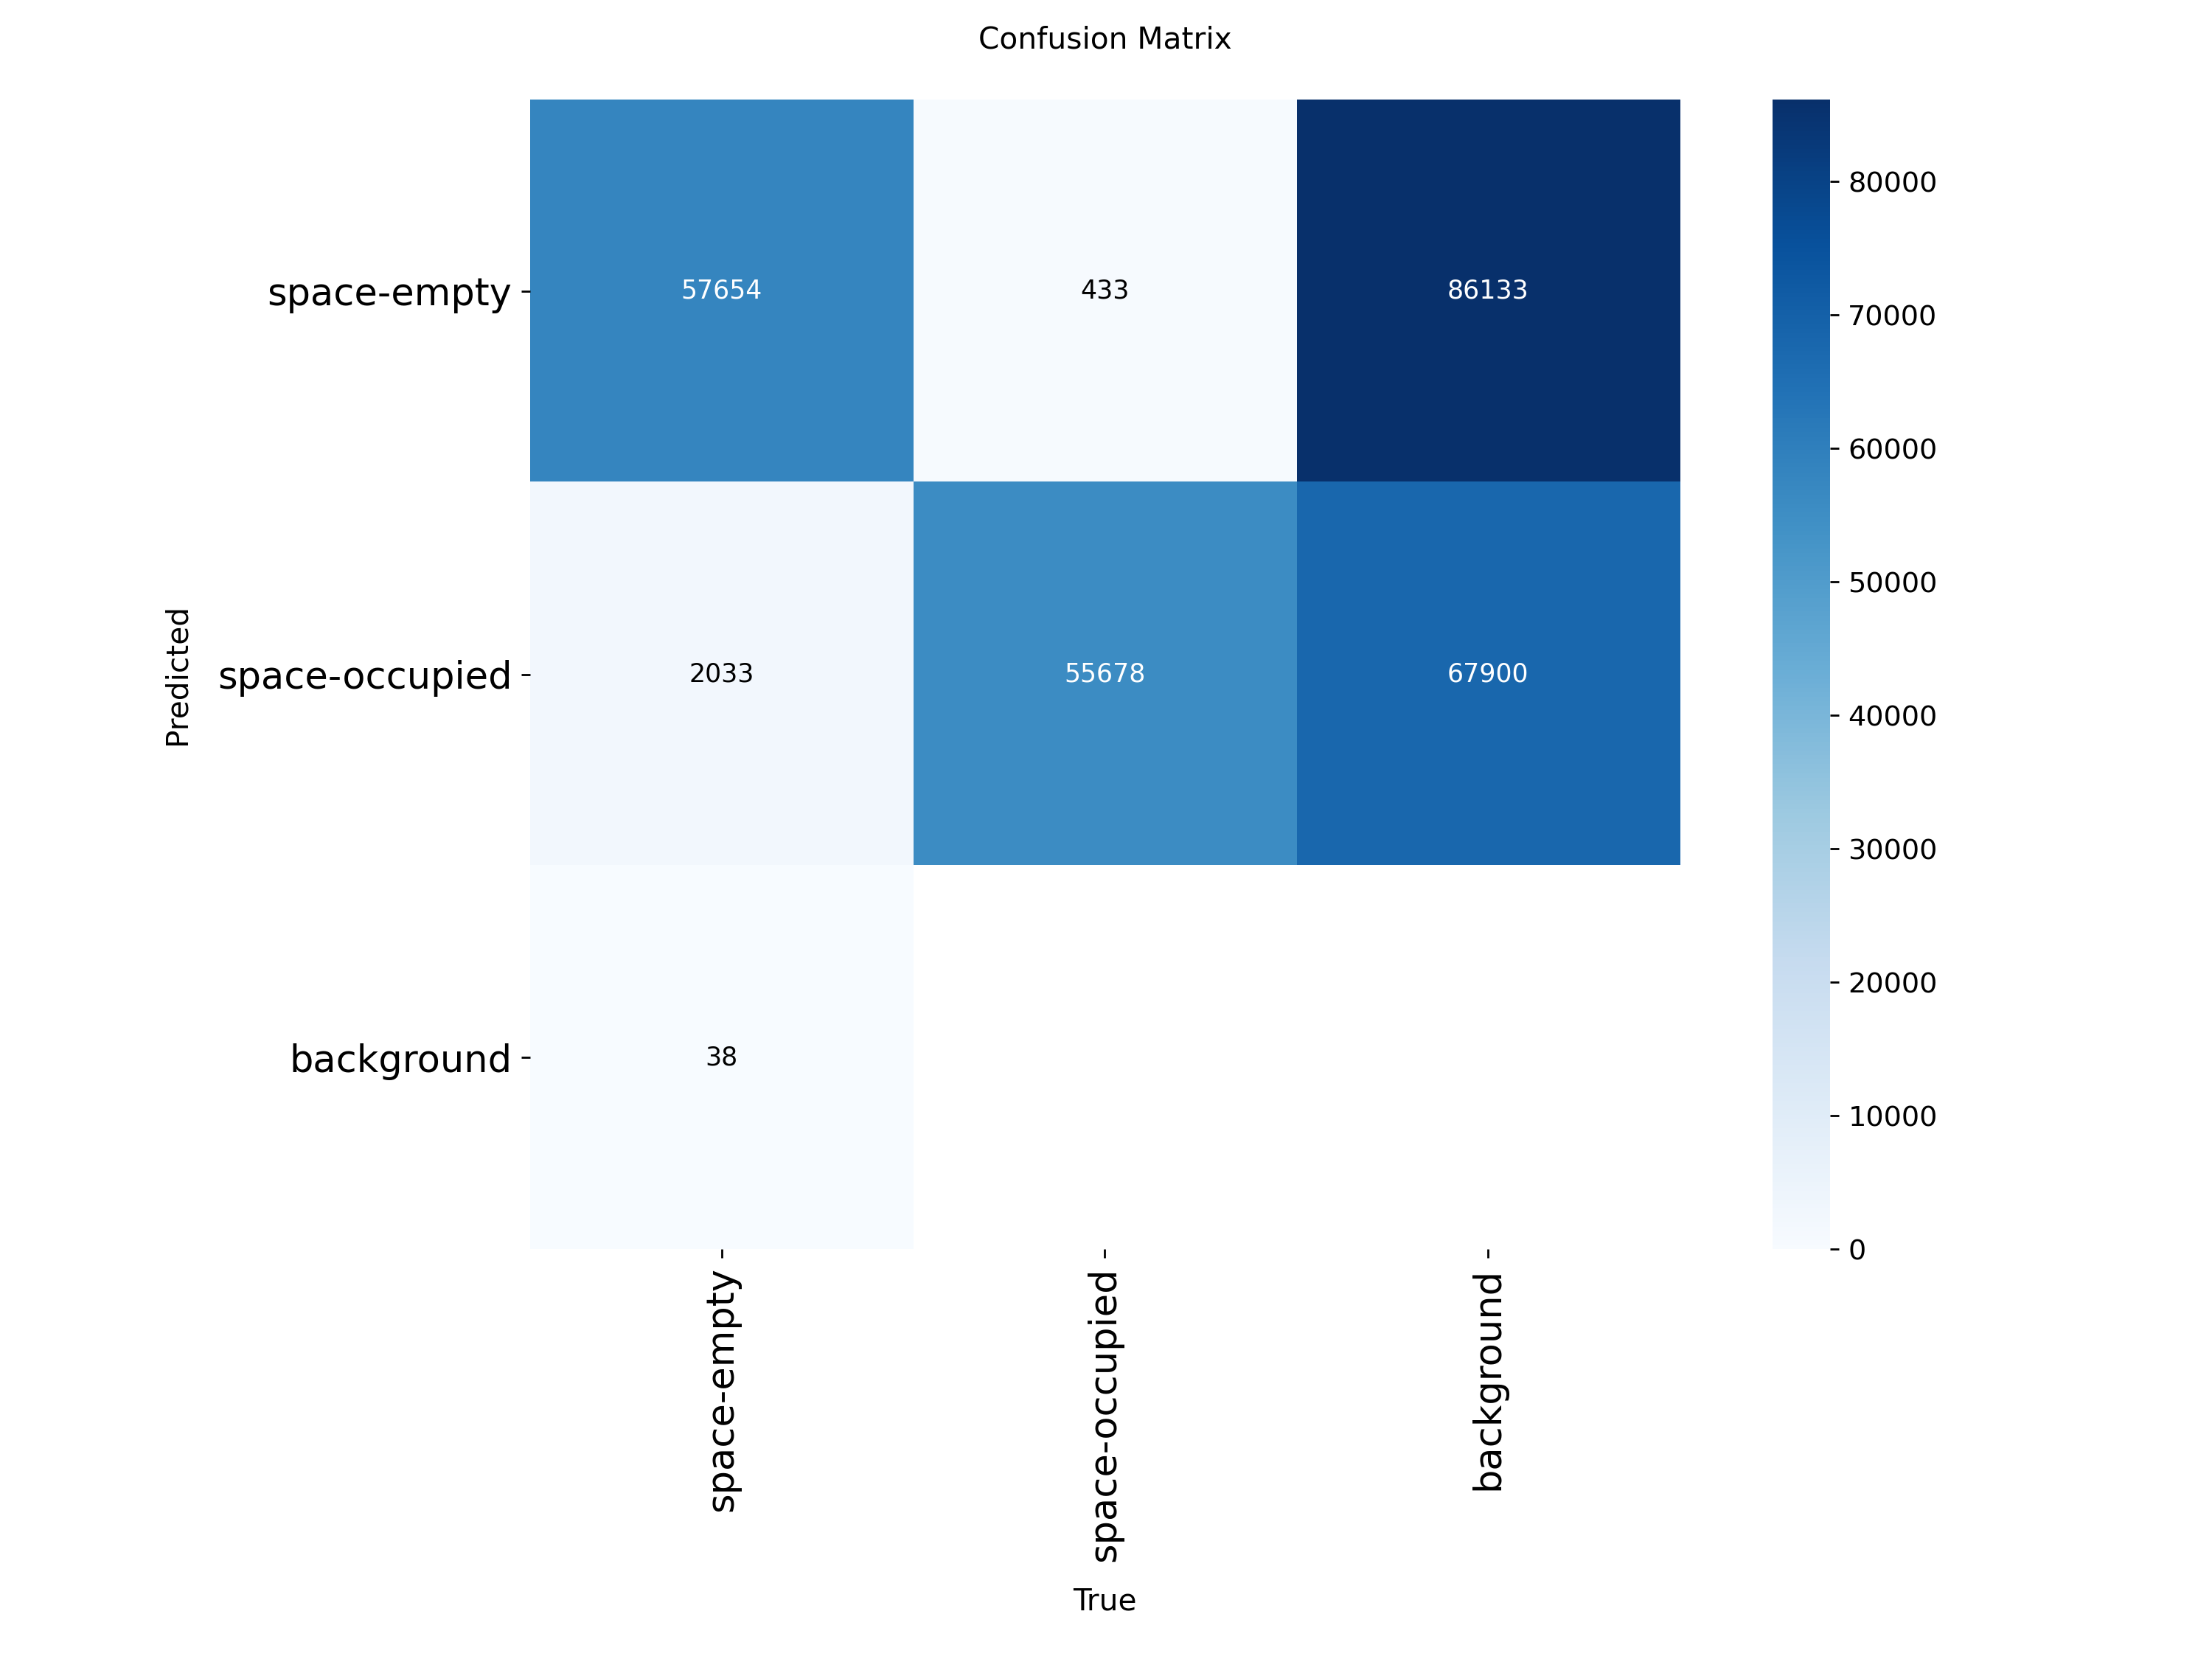

In [58]:
from IPython.display import Image, display

for f in ["results.png", "confusion_matrix.png"]:
    p = f"{RUN_DIR}/{f}"
    if os.path.exists(p):
        print(f); display(Image(p, width=800))

## Step 6: Test on images and count free spaces

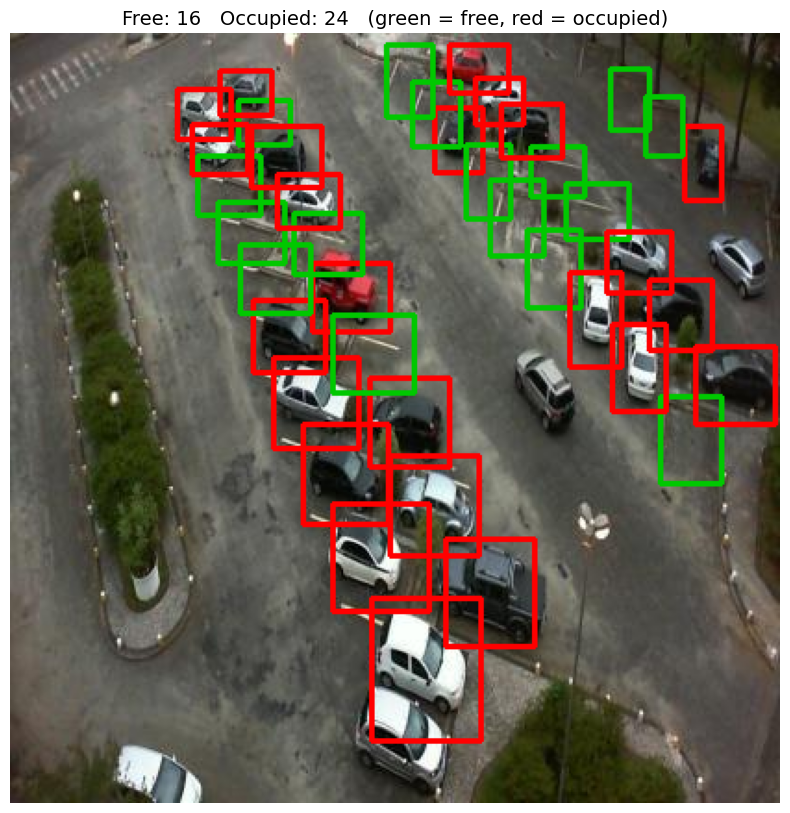

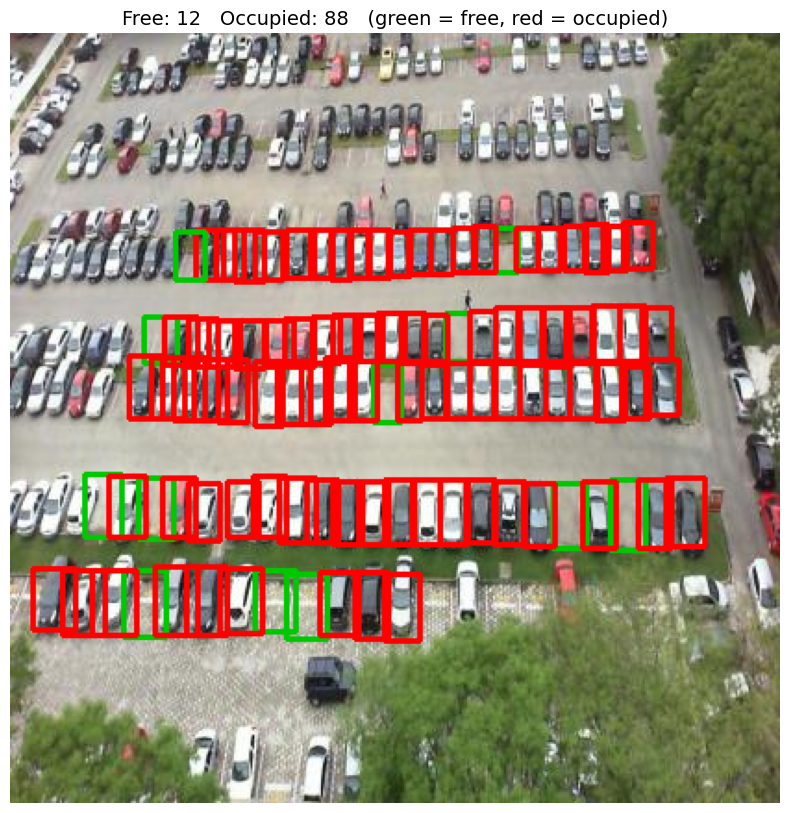

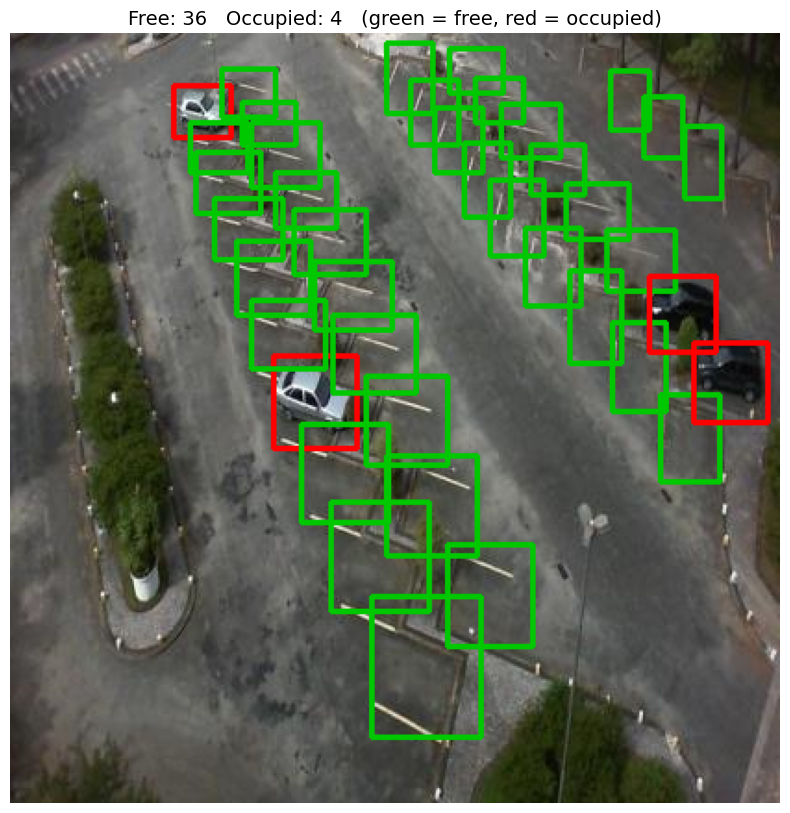

In [68]:
def count_spaces(result):
    """Count empty and occupied spaces in one YOLO result."""
    free = occupied = 0
    for c in result.boxes.cls.tolist():
        name = result.names[int(c)]
        if "empty" in name:
            free += 1
        elif "occupied" in name:
            occupied += 1
    return free, occupied

def draw_clean(result):
    """Draw thin green (free) and red (occupied) boxes, no text labels."""
    img = result.orig_img.copy()
    for box, c in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist()):
        x1, y1, x2, y2 = map(int, box)
        color = (0, 200, 0) if "empty" in result.names[int(c)] else (0, 0, 255)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    return img

test_imgs = random.sample(glob.glob(f"{DATA_DIR}/test/images/*"), 3)
for p in test_imgs:
    r = best.predict(p, conf=0.4, agnostic_nms=True, verbose=False)[0]
    free, occ = count_spaces(r)
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(draw_clean(r), cv2.COLOR_BGR2RGB))
    plt.title(f"Free: {free}   Occupied: {occ}   (green = free, red = occupied)", fontsize=14)
    plt.axis("off"); plt.show()

In [69]:
from google.colab import files
import shutil

os.makedirs("/content/results", exist_ok=True)

test_imgs = random.sample(glob.glob(f"{DATA_DIR}/test/images/*"), 6)
for i, p in enumerate(test_imgs, start=1):
    r = best.predict(p, conf=0.4, agnostic_nms=True, verbose=False)[0]
    free, occ = count_spaces(r)
    img = draw_clean(r)
    # write the counts on top of the picture
    cv2.rectangle(img, (0, 0), (260, 30), (0, 0, 0), -1)
    cv2.putText(img, f"Free: {free}  Occupied: {occ}", (8, 21),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    out = f"/content/results/detection_{i}.png"
    cv2.imwrite(out, img)
    print("Saved", out)

# also copy the training chart and confusion matrix
for f in ["results.png", "confusion_matrix.png"]:
    shutil.copy(f"{RUN_DIR}/{f}", f"/content/results/{f}")

# zip everything and download it
shutil.make_archive("/content/results", "zip", "/content/results")
files.download("/content/results.zip")

Saved /content/results/detection_1.png
Saved /content/results/detection_2.png
Saved /content/results/detection_3.png
Saved /content/results/detection_4.png
Saved /content/results/detection_5.png
Saved /content/results/detection_6.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7: Measure speed (less time-consuming detection)

**FPS** = frames per second. A higher number means faster detection. Report this in your presentation.

In [70]:
import time

imgs = glob.glob(f"{DATA_DIR}/test/images/*")[:50]
best.predict(imgs[0], verbose=False)       # warm-up run

start = time.time()
for p in imgs:
    best.predict(p, verbose=False)
elapsed = time.time() - start

print(f"Average time per image: {elapsed / len(imgs) * 1000:.1f} ms")
print(f"Speed: {len(imgs) / elapsed:.1f} FPS")

Average time per image: 11.8 ms
Speed: 84.5 FPS


In [72]:
from google.colab import files
uploaded = files.upload()
for name in uploaded:
    print("Uploaded:", name)

Saving 14292633_3840_2160_30fps.mp4 to 14292633_3840_2160_30fps.mp4
Uploaded: 14292633_3840_2160_30fps.mp4


## Step 8: Video demo

Upload a parking lot video (for example `parking.mp4`) using the Colab file panel on the left.

To save time, we only run detection **every N frames**, because cars in a parking lot don't move quickly. The other frames reuse the last result.

In [73]:
VIDEO_IN  = "14292633_3840_2160_30fps.mp4"
VIDEO_TMP = "parking_result_raw.mp4"
VIDEO_OUT = "parking_result.mp4"
DETECT_EVERY = 15      # run YOLO every 15 frames (about twice per second)
W, H = 1280, 720       # shrink 4K frames to 720p

cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
out = cv2.VideoWriter(VIDEO_TMP, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

frame_no, last = 0, None
start = time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frame = cv2.resize(frame, (W, H))
    if frame_no % DETECT_EVERY == 0:
        last = best.predict(frame, conf=0.4, agnostic_nms=True, verbose=False)[0]
    if last is not None:
        free, occ = count_spaces(last)
        for box, c in zip(last.boxes.xyxy.tolist(), last.boxes.cls.tolist()):
            x1, y1, x2, y2 = map(int, box)
            color = (0, 200, 0) if "empty" in last.names[int(c)] else (0, 0, 255)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        cv2.rectangle(frame, (10, 10), (360, 60), (0, 0, 0), -1)
        cv2.putText(frame, f"Free: {free}  Occupied: {occ}", (20, 45),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    out.write(frame)
    frame_no += 1

cap.release(); out.release()
print(f"Processed {frame_no} frames in {time.time() - start:.1f} s")

# convert so it plays on Mac (QuickTime) and in browsers
!ffmpeg -y -loglevel error -i {VIDEO_TMP} -c:v libx264 -preset veryfast -pix_fmt yuv420p {VIDEO_OUT}
print("Saved:", VIDEO_OUT)

Processed 227 frames in 17.6 s
Saved: parking_result.mp4


In [ ]:
from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("parking_result.mp4", "rb").read()).decode()
HTML(f'<video width=800 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

In [75]:
# Build a time-lapse demo video from PKLot test images (sorted by time)
frames = sorted(glob.glob(f"{DATA_DIR}/test/images/*"))[:150]
VIDEO_TMP, VIDEO_OUT = "timelapse_raw.mp4", "parking_timelapse.mp4"
SIZE = 832                         # upscale 416 -> 832 so it looks clearer

out = cv2.VideoWriter(VIDEO_TMP, cv2.VideoWriter_fourcc(*"mp4v"), 3, (SIZE, SIZE))
for p in frames:
    r = best.predict(p, conf=0.4, agnostic_nms=True, verbose=False)[0]
    free, occ = count_spaces(r)
    img = cv2.resize(draw_clean(r), (SIZE, SIZE))
    cv2.rectangle(img, (0, 0), (380, 45), (0, 0, 0), -1)
    cv2.putText(img, f"Free: {free}  Occupied: {occ}", (12, 32),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    out.write(img)
out.release()

!ffmpeg -y -loglevel error -i {VIDEO_TMP} -c:v libx264 -preset veryfast -pix_fmt yuv420p {VIDEO_OUT}
print("Saved:", VIDEO_OUT)

Saved: parking_timelapse.mp4


In [ ]:
from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("parking_timelapse.mp4", "rb").read()).decode()
HTML(f'<video width=700 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

In [78]:
from google.colab import files
files.download("parking_timelapse.mp4")
files.download("parking_result.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [79]:
from google.colab import files
files.download("parking_timelapse.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9: Simulated IoT message

In a real system, a small device (Raspberry Pi / Jetson Nano) next to the camera runs the model and sends a short message to a dashboard or app, usually with the **MQTT** protocol.

Here we **simulate** that: we build the JSON message the device would send. Only the counts are sent, not the video, which saves network bandwidth and protects privacy.

In [81]:
import json
from datetime import datetime

r = best.predict(random.choice(imgs), conf=0.4, verbose=False)[0]
free, occ = count_spaces(r)

message = {
    "lot_id": "LOT-A",
    "camera_id": "CAM-01",
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "free_spaces": free,
    "occupied_spaces": occ,
    "occupancy_rate": round(occ / max(free + occ, 1), 2),
}
print("MQTT topic: parking/LOT-A/status")
print(json.dumps(message, indent=2))

# Real MQTT version (optional, needs a broker such as test.mosquitto.org):
# !pip install -q paho-mqtt
# import paho.mqtt.publish as publish
# publish.single("parking/LOT-A/status", json.dumps(message), hostname="test.mosquitto.org")

MQTT topic: parking/LOT-A/status
{
  "lot_id": "LOT-A",
  "camera_id": "CAM-01",
  "timestamp": "2026-11-15T19:47:50",
  "free_spaces": 60,
  "occupied_spaces": 40,
  "occupancy_rate": 0.4
}


## Step 10: Save the model for IoT devices

Export to **ONNX**, a format that runs on many small devices (Raspberry Pi, Jetson).

In [82]:
best.export(format="onnx", imgsz=416)
print("Exported: runs/pklot_yolov8n/weights/best.onnx")

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 3.7 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/pklot_yolov8n/weights/best.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 6, 3549) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 289ms
Prepared 4 packages in 579ms
Installed 4 packages in 32ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: sl

In [83]:
from google.colab import files
files.download("/content/runs/detect/runs/pklot_yolov8n/weights/best.pt")
files.download("/content/runs/detect/runs/pklot_yolov8n/weights/best.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next steps

1. **Test on a new parking lot:** run the model on CNRPark-EXT images to see how well it works on camera angles it has never seen.
2. **Segmentation comparison:** train `yolov8n-seg.pt` using polygon labels (download PKLot in *YOLOv8 Instance Segmentation* format if available).
3. **Classification comparison:** crop each space and train a small CNN (MobileNetV2) to label it empty or occupied.
4. **Results table for the presentation:** precision, recall, mAP50 and FPS for each approach.